# Results

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 
Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


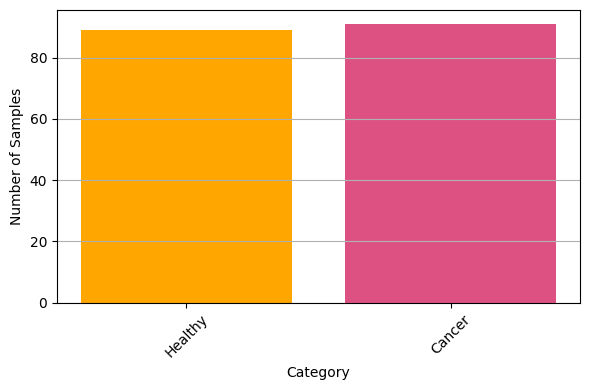


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


In [2]:
class_task = "healthy_vs_cancer"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

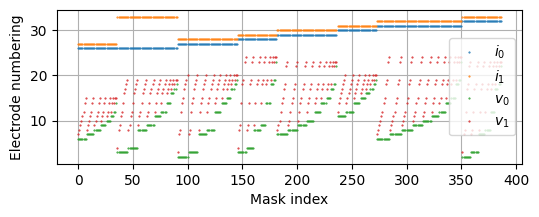

(180, 774)


In [3]:
Msel = "Med. adj."
Fsel = "Top 2"
m = SVC(kernel="rbf", C=1.0, probability=True)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [4]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

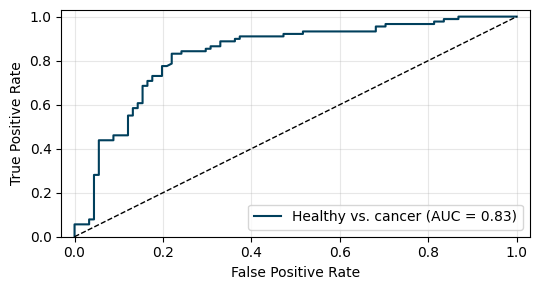

In [5]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_SVM.pdf"
)

**RF**

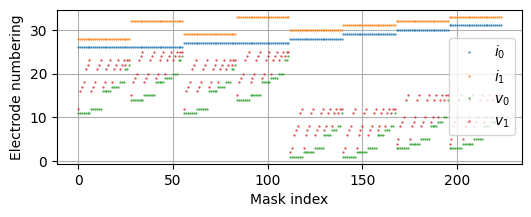

(180, 1120)


In [6]:
Msel = "Skip1 far"
Fsel = "Top 5"
m = RandomForestClassifier(
    n_estimators=100,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=4,
)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [7]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

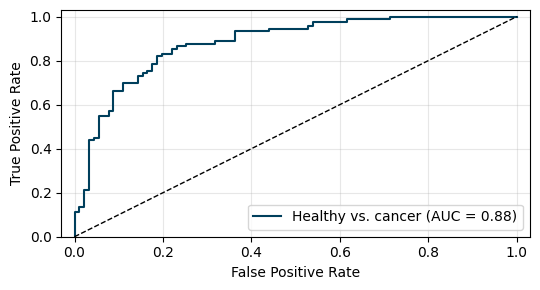

In [8]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_RF.pdf"
)

**LR**

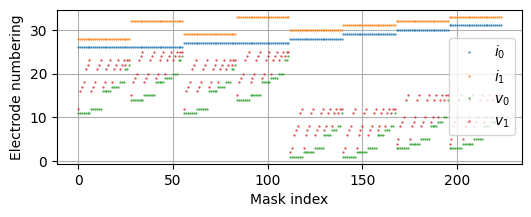

(180, 2688)


In [9]:
Msel = "Skip1 far"
Fsel = "Top 12"
m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [10]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

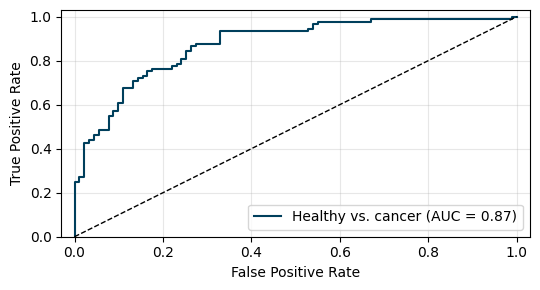

In [11]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_LR.pdf"
)

## Task 2 : Cancer versus HBD


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 

Healthy vs. HDB

Non-cancer: 137 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Non-cancer']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Non-cancer'): [0, 1]}


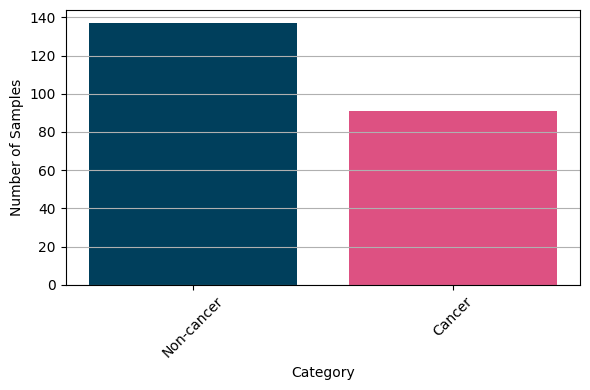


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Non-cancer'}
(228, 31, 7728) (228, 2) (228,)


In [12]:
class_task = "cancer_vs_hbd"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

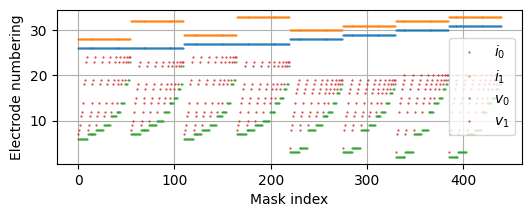

(228, 1320)


In [13]:
Msel = "Skip1 medium"
Fsel = "Top 3"
m = SVC(kernel="linear", C=0.001, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [14]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

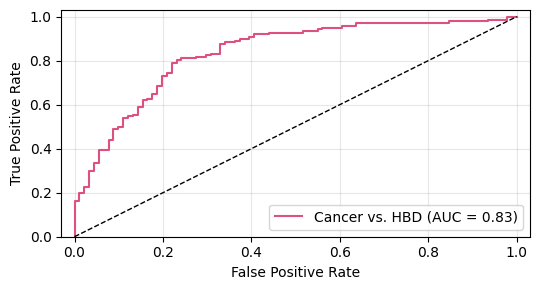

In [15]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_SVM.pdf"
)

**RF**

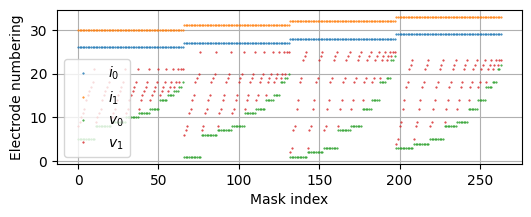

(228, 528)


In [16]:
Msel = "Opp. medium"
Fsel = "Top 2"
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=4,
)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [17]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

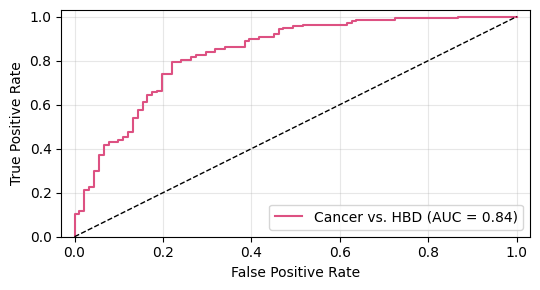

In [18]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_RF.pdf"
)

**LR**

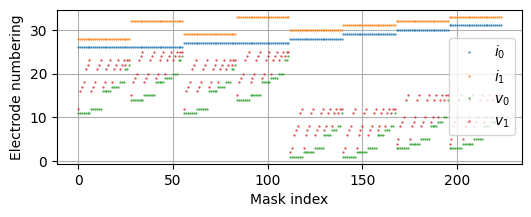

(228, 2688)


In [19]:
Msel = "Skip1 far"  # TBD
Fsel = "Top 12"
m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [20]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

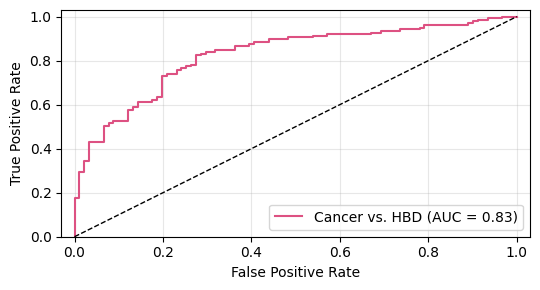

In [21]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_LR.pdf"
)

## Task 3: Multiclass

**TBD**: Implementation of train-test split with augmentation before doing data augmentation.

In [22]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 

MC

Healthy: 89 entries
Cancer: 91 entries
Severe dysplasia: 24 entries
Benign: 22 entries
Available cases: ['Benign' 'Cancer' 'Healthy' 'Severe dysplasia']
Coding: -> forward
{np.str_('Benign'): [1, 0, 0, 0], np.str_('Cancer'): [0, 1, 0, 0], np.str_('Healthy'): [0, 0, 1, 0], np.str_('Severe dysplasia'): [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Benign', (0, 1, 0, 0): 'Cancer', (0, 0, 1, 0): 'Healthy', (0, 0, 0, 1): 'Severe dysplasia'}
(226, 31, 7728) (226, 4) (226,)


**SVM**

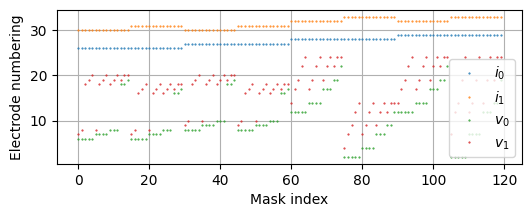

(226, 240)


In [23]:
Msel = "Med. a+ ext."
Fsel = "Top 2"
m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [24]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

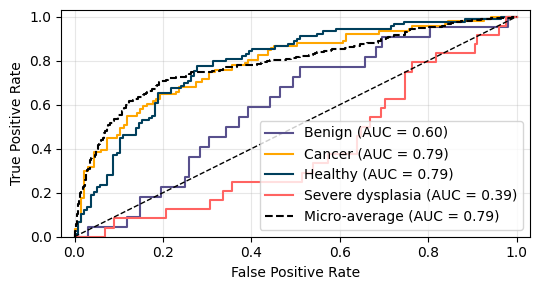

In [25]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_SVM.pdf"
)

**RF**

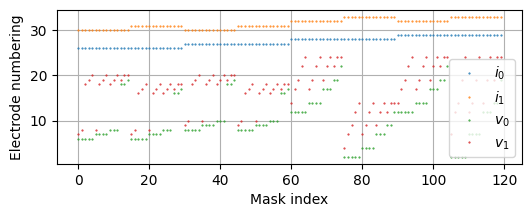

(226, 360)


In [26]:
Msel = "Med. a+ ext."
Fsel = "Top 3"
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=1,
)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [27]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

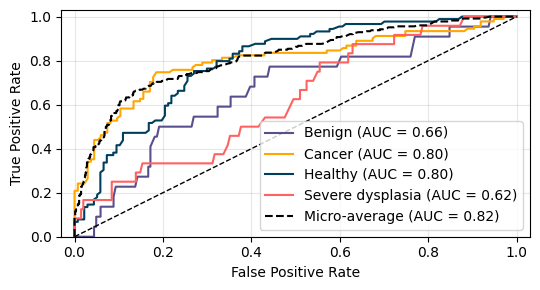

In [28]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_RF.pdf"
)

**LR**

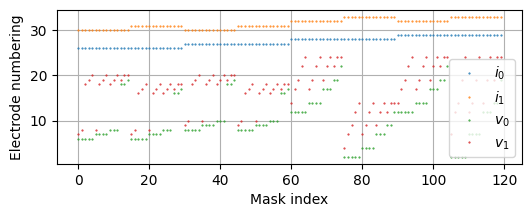

(226, 360)


In [29]:
Msel = "Med. a+ ext."  # TBD
Fsel = "Top 3"  # TBD
m = LogisticRegression(C=1.0, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [30]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

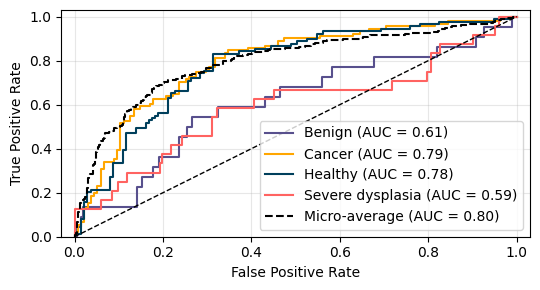

In [31]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_LR.pdf"
)

___